# Figure S8
### Cropland area in 2071-2100 under the 4 SSPs
Source of data: LUH2

In [3]:
import xarray as xr
import numpy as np
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import cartopy.feature as cfeature
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.cm import ScalarMappable
import colormaps as cmaps

FUTURE_YEARS = slice(2071, 2100)
SSPS = ["ssp126", "ssp245", "ssp370", "ssp585"]

In [15]:
# Filepaths of Land Use Harmonization 2 (LUH2) data for each experiment
basedir = "/work10/archive/CMIP6/CMIP-SSPs/inputs/LandUse"
exp_LUH2path = {
    "historical": f"{basedir}/LUH2_v2h_historical/states_LUH2_v2h_historical_850_2015.nc",
    "ssp126": f"{basedir}/LUH2_v2f_future_states/multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-IMAGE-ssp126-2-1-f_gn_2015-2100.nc",
    "ssp245": f"{basedir}/LUH2_v2f_future_states/multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-MESSAGE-ssp245-2-1-f_gn_2015-2100.nc",
    "ssp370": f"{basedir}/LUH2_v2f_future_states/multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-AIM-ssp370-2-1-f_gn_2015-2100.nc",
    "ssp585": f"{basedir}/LUH2_v2f_future_states/multiple-states_input4MIPs_landState_ScenarioMIP_UofMD-MAGPIE-ssp585-2-1-f_gn_2015-2100.nc",
}

def get_crop_data(exp, exp_to_path = exp_LUH2path, chunks=None) -> xr.DataArray:
    """Returns a DataArray with the fraction of each grid cell occupied by
     cropland in the given experiment. The data comes from Land Use Harmonization 2 (LUH2), see
      https://luh.umd.edu/ or Hurtt et al. 2020 fo further info."""

    path = exp_to_path[exp]
    ds = xr.open_dataset(path, decode_times=False, chunks=chunks)

    ds = ds.rename({'time': 'year'})

    if exp == "historical":
        # historical land use data covers 850 to 2015, so year 0 = 850 and year 1166 = 2015
        ds['year'] = ds.year.astype(int) + 850
        ds = ds.sel(year=slice('1981', '2014')) # we only care about this period
    else:
        # ssp land use data covers 2015 to 2100, so year 0 = 2015 and year 86 = 2100
        ds['year'] = ds.year.astype(int) + 2015


    # Sum all types of crops
    crop_vars = ['c3ann', 'c4ann', 'c3per', 'c4per', 'c3nfx']
    crops = ds[crop_vars].to_dataarray(dim="crop_fraction").sum("crop_fraction")

    return crops

# --- Data: end-of-century mean cropland fraction (%) per SSP ---------------------------------
def get_crop_pct(exp, years=FUTURE_YEARS):
    crops = get_crop_data(exp).sel(year=years).mean("year") * 100

    # .sum() in get_crop_data turns ocean NaNs into 0, so re-mask ocean using the LUH2 land mask
    with xr.open_dataset(exp_LUH2path[exp], decode_times=False) as ds:
        land = ds["c3ann"].isel(time=0).notnull().load()
    return crops.where(land).sortby("lat")

crop_pct = {exp: get_crop_pct(exp) for exp in SSPS}

/work/home/H.mvelasco/miniconda3/envs/work/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/work/home/H.mvelasco/miniconda3/envs/work/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/work/home/H.mvelasco/miniconda3/envs/work/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/work/home/H.mvelasco/miniconda3/envs/work/lib/python3.14/site-packages/cartopy/mpl/feature_artist.py:143: UserWarning: facecolor will have no effect as it has been defined as "never".
  warnings.warn('facecolor will have no effect as it has been '
/tmp

  ✓ png/FigureS8.png
  ✓ pdf/FigureS8.pdf


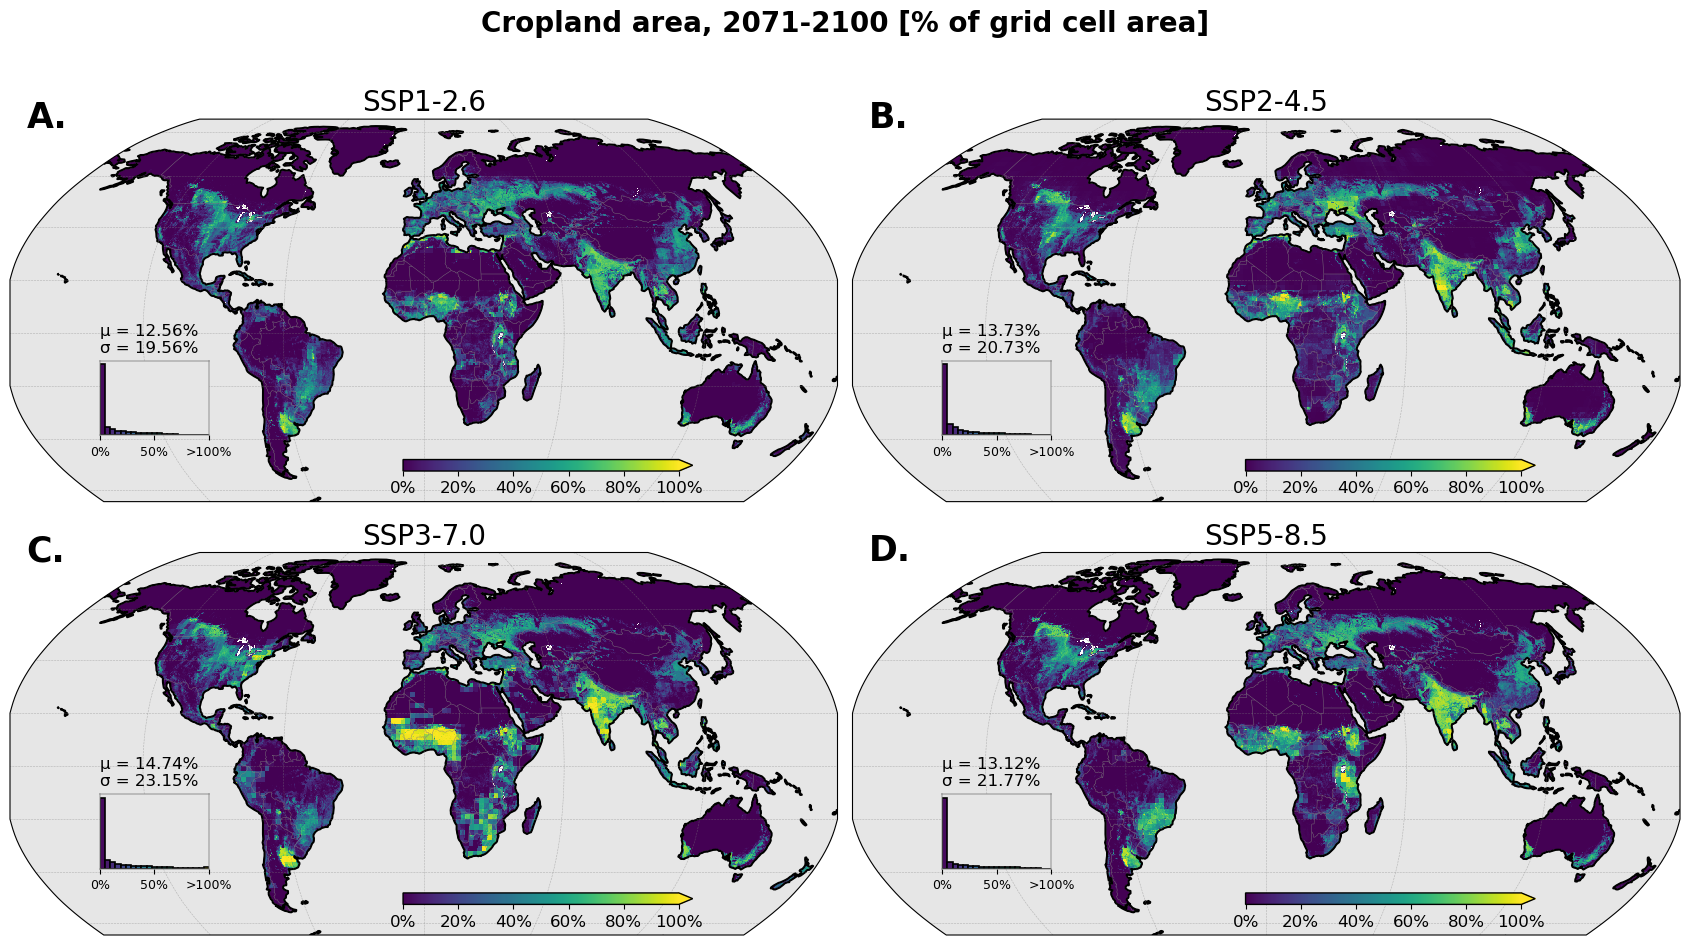

In [18]:
import sys
sys.path.insert(0, '../') # Trick to import code from parent folder
from plot_utils import plot_panel

#  2x2 subplot
fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 10),
    subplot_kw={"projection": ccrs.Robinson()}
)

axes = axes.flatten()

VMIN = 0
VMAX = 100
CMAP = plt.colormaps.get_cmap('viridis')

# panel A. SSP1-2.6
plot_panel(
    axes[0],
    crop_pct['ssp126'],
    r"SSP1-2.6",
    vmin=VMIN,
    vmax=VMAX,
    cmap=CMAP,
    extend="max", 
    label="A.",
    anom_type="relative",
)

# panel B. SSP2-4.5
plot_panel(
    axes[1],
    crop_pct['ssp245'],
    r"SSP2-4.5",
    vmin=VMIN,
    vmax=VMAX,
    cmap=CMAP,
    extend="max", 
    label="B.",
    anom_type="relative",
)

# panel C. SSP3-7.0
plot_panel(
    axes[2],
    crop_pct['ssp370'],
    r"SSP3-7.0",
    vmin=VMIN,
    vmax=VMAX,
    cmap=CMAP,
    extend="max", 
    label="C.",
    anom_type="relative",
)

# panel C. SSP5-8.5
plot_panel(
    axes[3],
    crop_pct['ssp585'],
    r"SSP5-8.5",
    vmin=VMIN,
    vmax=VMAX,
    cmap=CMAP,
    extend="max", 
    label="D.",
    anom_type="relative",
)

suptitle = r"Cropland area, 2071-2100 [% of grid cell area]" + "\n"
fig.suptitle(suptitle, fontsize=20, fontweight="bold")
plt.tight_layout()

# Save as png and pdf
for ext in ["png", "pdf"]:
        filename = f"{ext}/FigureS8.{ext}"
        fig.savefig(filename, dpi=500, bbox_inches="tight", pad_inches=0.3)
        print(f"  ✓ {filename}")

plt.show()